# Notebook 01 — CIFAR-10 Federated Learning & Membership Inference Attack
**MSc Thesis | Evaluating Black-Box MIA in Federated Learning**

This notebook implements the complete experimental pipeline for the CIFAR-10 dataset. It is fully self-contained — just run all cells from top to bottom.

## What this notebook does:

- Loads and preprocesses CIFAR-10 (50,000 training / 10,000 test, 10 classes)
- Partitions data across federated clients using IID partitioning
- Simulates federated learning using the FedAvg algorithm
- Evaluates black-box membership inference attacks against the trained global model
- Addresses four research questions:
  - **RQ1:** Can a black-box MIA succeed against a federated learning model?
  - **RQ2:** How does the number of clients affect attack success?
  - **RQ3:** How does model complexity affect privacy leakage?
  - **RQ8:** Does FedAvg provide privacy benefit over centralised (single-node) training?

**Configuration:** 5 clients | 10 communication rounds | 3 local epochs per round


## 1. Imports & Configuration


In [1]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import json, os, gc

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import recall_score, roc_auc_score

import matplotlib.pyplot as plt

# ── Experiment configuration ──────────────────────────────────────────────────
NUM_CLIENTS   = 5
NUM_ROUNDS    = 10
LOCAL_EPOCHS  = 3
BATCH_SIZE    = 64
LEARNING_RATE = 0.001
NUM_CLASSES   = 10
RANDOM_SEED   = 42

np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)
gc.collect()
tf.keras.backend.clear_session()

OUTPUT_DIR = "/content/outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print(f"TensorFlow : {tf.__version__}")
print(f"GPU        : {tf.config.list_physical_devices('GPU')}")
print(f"Config     : {NUM_CLIENTS} clients | {NUM_ROUNDS} rounds | {LOCAL_EPOCHS} local epochs")


TensorFlow : 2.21.0
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Config     : 5 clients | 10 rounds | 3 local epochs


## 2. Load & Preprocess CIFAR-10


In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
x_train = x_train.astype('float32') / 255.0
x_test  = x_test.astype('float32')  / 255.0
y_train = y_train.flatten()
y_test  = y_test.flatten()

print(f"Training set : {x_train.shape}  labels: {y_train.shape}")
print(f"Test set     : {x_test.shape}   labels: {y_test.shape}")


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2355s 14us/step
Training set : (50000, 32, 32, 3)  labels: (50000,)
Test set     : (10000, 32, 32, 3)   labels: (10000,)


## 3. Helper Functions

This section defines all reusable functions for the pipeline:
- `partition_data_iid` — splits training data equally across clients
- `build_model` — defines the CNN architecture (small or large)
- `fedavg_aggregate` — computes weighted average of client weights
- `local_train` — trains a client model for one round
- `train_attack_model` — trains and evaluates the logistic regression attacker
- `run_fl_and_attack` — runs the full pipeline end to end (used for RQ2 & RQ3)


In [3]:
def partition_data_iid(x, y, num_clients, seed=42):
    """Shuffle and split data equally across clients (IID partitioning)."""
    rng     = np.random.default_rng(seed)
    indices = rng.permutation(len(x))
    splits  = np.array_split(indices, num_clients)
    client_data    = [(x[idx], y[idx]) for idx in splits]
    client_indices = [idx.tolist() for idx in splits]
    return client_data, client_indices


def build_model(num_classes=10, learning_rate=0.001, complexity='small'):
    """
    CNN for CIFAR-10 classification.
    complexity: 'small' (2 conv blocks) or 'large' (4 conv layers)
    """
    if complexity == 'small':
        model = keras.Sequential([
            layers.Input(shape=(32, 32, 3)),
            layers.Conv2D(32, (3,3), activation='relu', padding='same'),
            layers.MaxPooling2D(),
            layers.Conv2D(64, (3,3), activation='relu', padding='same'),
            layers.MaxPooling2D(),
            layers.Flatten(),
            layers.Dense(128, activation='relu'),
            layers.Dropout(0.3),
            layers.Dense(num_classes, activation='softmax'),
        ])
    else:
        model = keras.Sequential([
            layers.Input(shape=(32, 32, 3)),
            layers.Conv2D(64,  (3,3), activation='relu', padding='same'),
            layers.Conv2D(64,  (3,3), activation='relu', padding='same'),
            layers.MaxPooling2D(),
            layers.Conv2D(128, (3,3), activation='relu', padding='same'),
            layers.Conv2D(128, (3,3), activation='relu', padding='same'),
            layers.MaxPooling2D(),
            layers.Flatten(),
            layers.Dense(256, activation='relu'),
            layers.Dropout(0.4),
            layers.Dense(num_classes, activation='softmax'),
        ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model


def fedavg_aggregate(client_weights, client_sizes):
    """Weighted average of client model weights proportional to dataset size."""
    total = sum(client_sizes)
    return [
        sum((s / total) * w for w, s in zip(layer_ws, client_sizes))
        for layer_ws in zip(*client_weights)
    ]


def local_train(global_weights, x_c, y_c, local_epochs,
                batch_size, lr, complexity='small'):
    """Train a local client model starting from the current global weights."""
    m = build_model(learning_rate=lr, complexity=complexity)
    m.set_weights(global_weights)
    m.fit(x_c, y_c, epochs=local_epochs, batch_size=batch_size, verbose=0)
    return m.get_weights()


def run_fl_and_attack(num_clients, num_rounds=6, local_epochs=2,
                      batch_size=64, lr=0.001, complexity='small',
                      seed=42, n_attack_samples=1000):
    """Full pipeline: FL training → attack data collection → attacker evaluation."""
    gc.collect()
    tf.keras.backend.clear_session()

    client_data, client_indices = partition_data_iid(x_train, y_train, num_clients, seed)
    member_idx   = [i for sublist in client_indices for i in sublist]
    client_sizes = [len(xc) for xc, _ in client_data]

    gm = build_model(learning_rate=lr, complexity=complexity)
    gw = gm.get_weights()
    for _ in range(num_rounds):
        cw_list = [local_train(gw, xc, yc, local_epochs, batch_size, lr, complexity)
                   for xc, yc in client_data]
        gw = fedavg_aggregate(cw_list, client_sizes)
        gm.set_weights(gw)

    rng    = np.random.default_rng(seed)
    m_idx  = rng.choice(member_idx,  size=n_attack_samples, replace=False)
    nm_idx = rng.choice(len(x_test), size=n_attack_samples, replace=False)
    m_probs  = gm.predict(x_train[m_idx],  batch_size=256, verbose=0)
    nm_probs = gm.predict(x_test[nm_idx],  batch_size=256, verbose=0)
    X_atk = np.vstack([m_probs, nm_probs])
    y_atk = np.array([1]*n_attack_samples + [0]*n_attack_samples)

    from sklearn.metrics import roc_auc_score, recall_score
    scores = np.max(X_atk, axis=1)
    labels = np.array([1]*n_attack_samples + [0]*n_attack_samples)
    auc    = roc_auc_score(labels, scores)
    preds  = (scores > np.median(scores)).astype(int)
    recall = recall_score(labels, preds, zero_division=0)
    _, acc = gm.evaluate(x_test, y_test, verbose=0)
    return {'auc': auc, 'recall': recall, 'global_acc': acc}

    del gm, cw_list, m_probs, nm_probs, X_atk
    gc.collect()


print("All helper functions defined.")

All helper functions defined.


## 4. Federated Learning Training (RQ1 Baseline)

The global model is trained using FedAvg across 5 clients for 10 communication rounds.
Each client trains locally for 3 epochs on its private data partition before sending
weight updates to the central server for aggregation.


  Client 1: 10000 samples
  Client 2: 10000 samples
  Client 3: 10000 samples
  Client 4: 10000 samples
  Client 5: 10000 samples

Starting federated training...

Round 01/10 | Test accuracy: 0.4644 | Loss: 1.8255
Round 02/10 | Test accuracy: 0.6083 | Loss: 1.1132
Round 03/10 | Test accuracy: 0.6507 | Loss: 0.9894
Round 04/10 | Test accuracy: 0.6783 | Loss: 0.9214
Round 05/10 | Test accuracy: 0.6992 | Loss: 0.8768
Round 06/10 | Test accuracy: 0.7058 | Loss: 0.8540
Round 07/10 | Test accuracy: 0.7103 | Loss: 0.8447
Round 08/10 | Test accuracy: 0.7153 | Loss: 0.8549
Round 09/10 | Test accuracy: 0.7159 | Loss: 0.8667
Round 10/10 | Test accuracy: 0.7160 | Loss: 0.8903

Federated training complete. Final accuracy: 0.7160


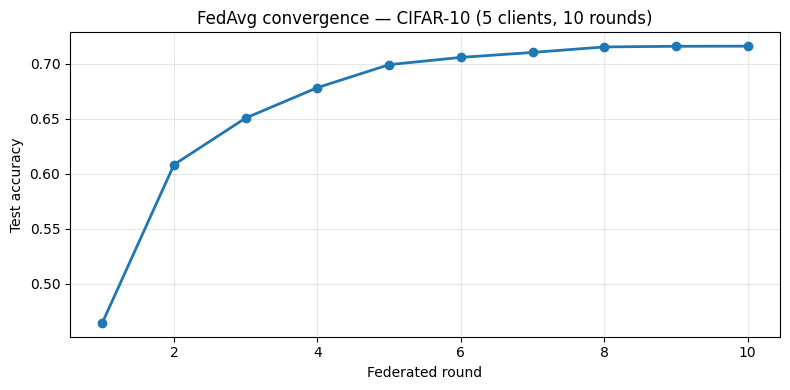

In [4]:
client_data, client_indices = partition_data_iid(x_train, y_train, NUM_CLIENTS, RANDOM_SEED)
member_indices = [i for sublist in client_indices for i in sublist]
client_sizes   = [len(xc) for xc, _ in client_data]

for i, (xc, yc) in enumerate(client_data):
    print(f"  Client {i+1}: {xc.shape[0]} samples")

global_model   = build_model(num_classes=NUM_CLASSES, learning_rate=LEARNING_RATE)
global_weights = global_model.get_weights()
round_accuracies = []

print("\nStarting federated training...\n")
for round_num in range(1, NUM_ROUNDS + 1):
    cw_list = [
        local_train(global_weights, xc, yc, LOCAL_EPOCHS, BATCH_SIZE, LEARNING_RATE)
        for xc, yc in client_data
    ]
    global_weights = fedavg_aggregate(cw_list, client_sizes)
    global_model.set_weights(global_weights)
    loss, acc = global_model.evaluate(x_test, y_test, verbose=0)
    round_accuracies.append(acc)
    print(f"Round {round_num:02d}/{NUM_ROUNDS} | Test accuracy: {acc:.4f} | Loss: {loss:.4f}")

print(f"\nFederated training complete. Final accuracy: {round_accuracies[-1]:.4f}")

# Plot convergence
plt.figure(figsize=(8, 4))
plt.plot(range(1, NUM_ROUNDS+1), round_accuracies, marker='o', linewidth=2)
plt.xlabel("Federated round")
plt.ylabel("Test accuracy")
plt.title(f"FedAvg convergence — CIFAR-10 ({NUM_CLIENTS} clients, {NUM_ROUNDS} rounds)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'cifar10_convergence.png'), dpi=150)
plt.show()


## 5. Build the Attacker Dataset

The attacker has **black-box access** — they can only query the global model
and observe the softmax output probabilities. They cannot see model weights or gradients.

- **Members** (label = 1): samples used during FL training
- **Non-members** (label = 0): unseen test samples

The attacker's feature vector for each sample is the model's full 10-dimensional
softmax output — one confidence score per class.


In [5]:
rng = np.random.default_rng(RANDOM_SEED)
n   = 5000

m_idx  = rng.choice(member_indices, size=n, replace=False)
nm_idx = rng.choice(len(x_test),    size=n, replace=False)

print("Querying model on member samples...")
m_probs  = global_model.predict(x_train[m_idx],  batch_size=256, verbose=1)
print("Querying model on non-member samples...")
nm_probs = global_model.predict(x_test[nm_idx],  batch_size=256, verbose=1)

X_attack = np.vstack([m_probs, nm_probs])
y_attack = np.array([1]*n + [0]*n)

print(f"\nAttacker dataset: {X_attack.shape} — {n} members + {n} non-members")


Querying model on member samples...
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step
Querying model on non-member samples...
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

Attacker dataset: (10000, 10) — 5000 members + 5000 non-members


## 6. RQ1 — Train the Attacker & Evaluate

A logistic regression classifier is trained as the black-box attacker.
It takes the model's softmax output vector as input and predicts member (1) or non-member (0).

**Metrics reported:**
- **AUC** — how well the attacker ranks members above non-members (0.50 = random chance)
- **Recall** — proportion of actual members the attacker correctly identified (0.50 = random chance)


── RQ1 Attack Results (CIFAR-10, 5 clients, FedAvg) ────────────────────
  Global Accuracy   : 0.7160
  Threshold AUC     : 0.5357  (random chance = 0.50)
  Loss-based AUC    : 0.5357  (random chance = 0.50)
────────────────────────────────────────────────────────────────────────


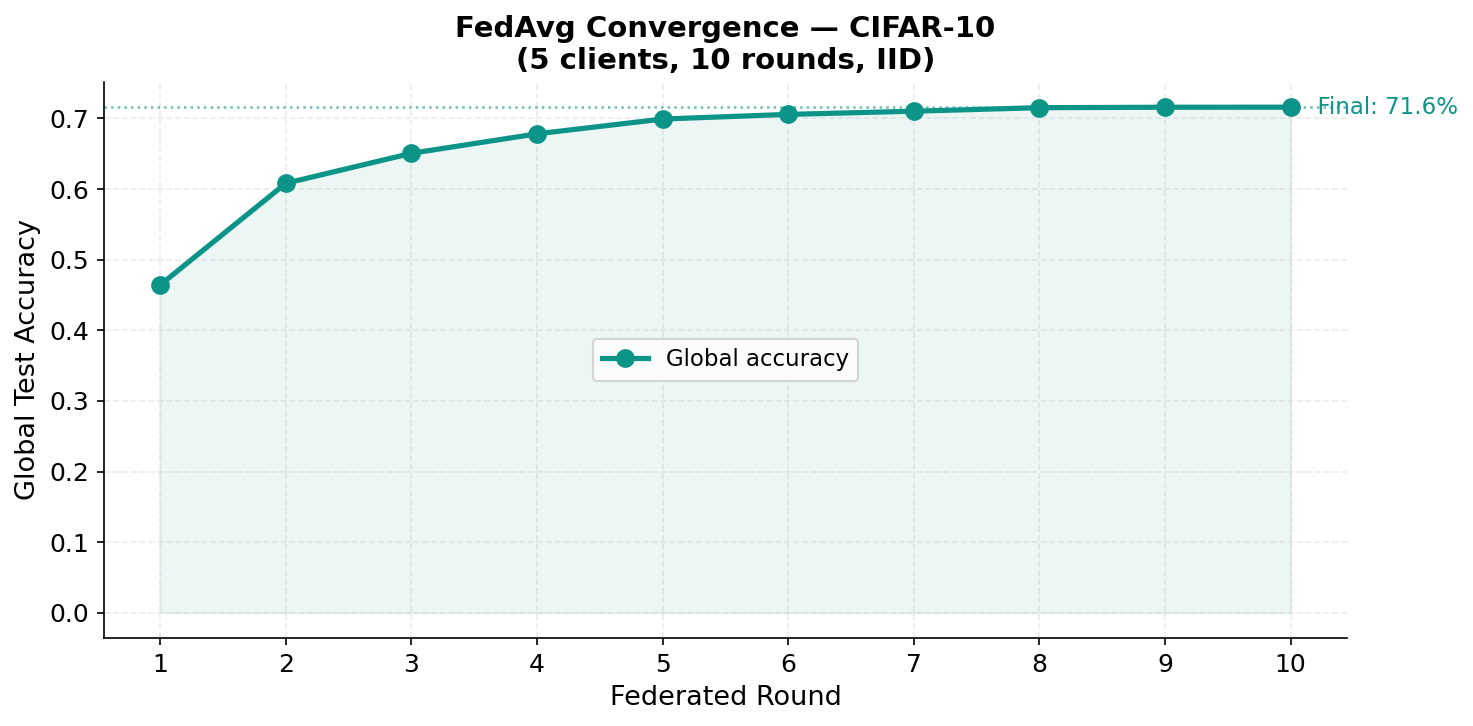

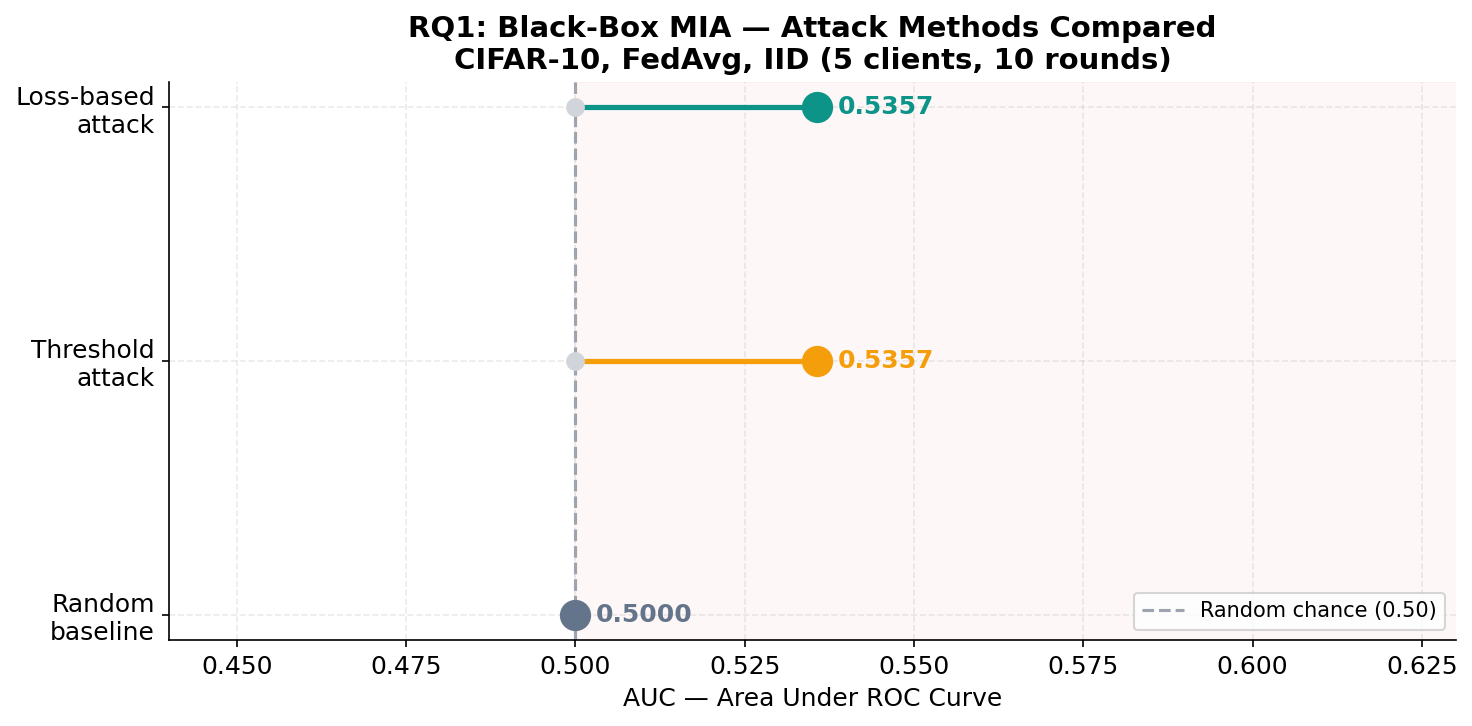

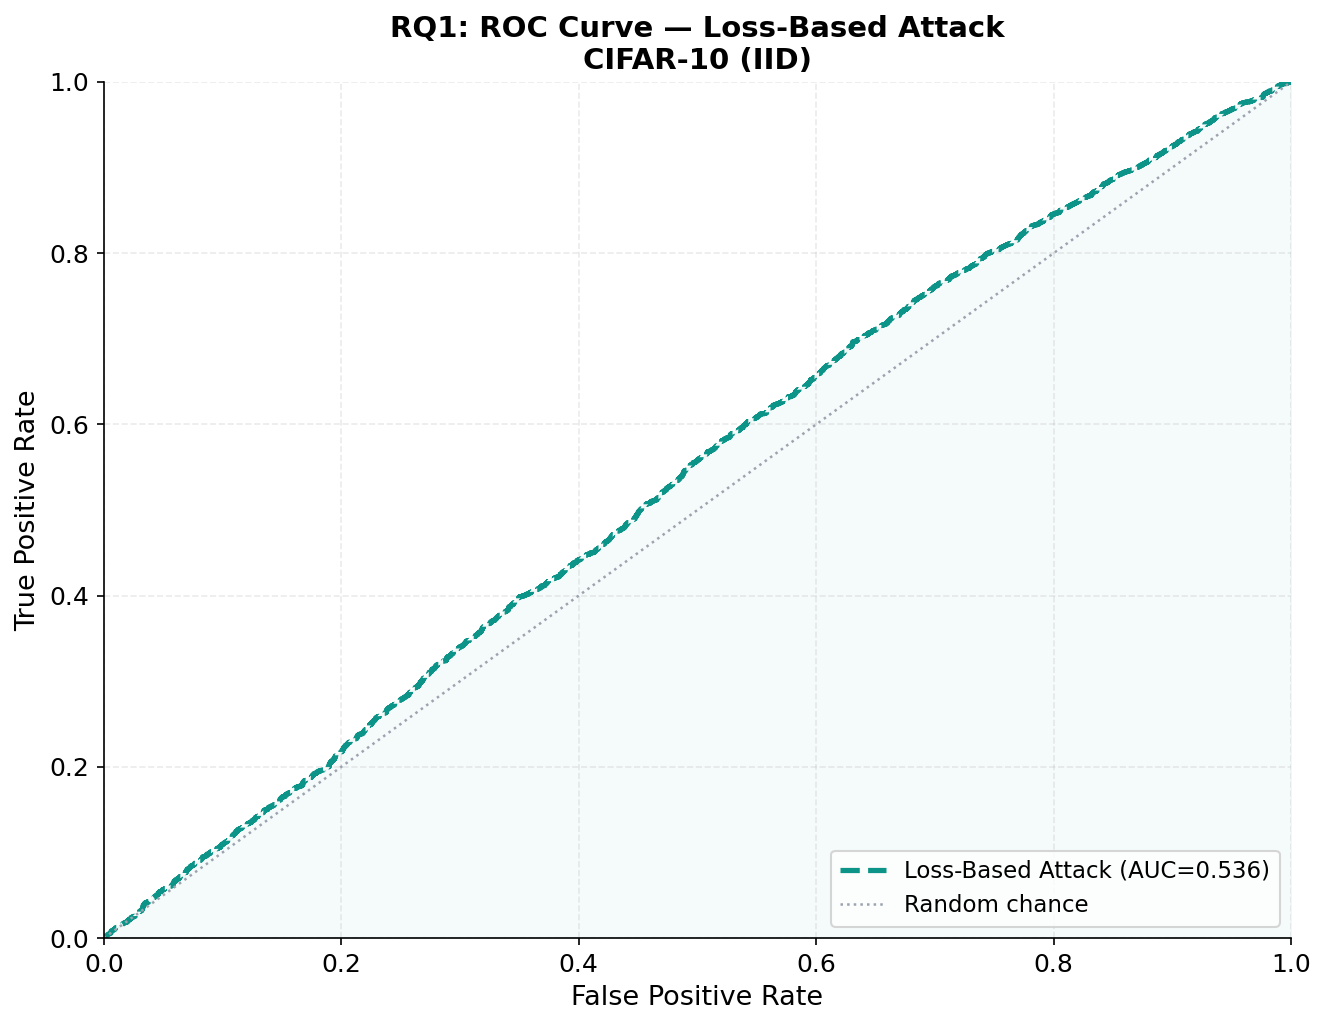

RQ1 — Threshold: 0.5357 | Loss: 0.5357


In [6]:
# ── Plot style ───────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from sklearn.metrics import roc_curve, roc_auc_score

plt.rcParams.update({
    'font.family':       'DejaVu Sans',
    'font.size':         12,
    'axes.titlesize':    14,
    'axes.titleweight':  'bold',
    'axes.labelsize':    12,
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'axes.grid':         True,
    'grid.alpha':        0.25,
    'grid.linestyle':    '--',
    'figure.dpi':        150,
    'savefig.dpi':       150,
    'savefig.bbox':      'tight',
    'savefig.facecolor': 'white',
})
TEAL  = '#0D9488'
NAVY  = '#0D1B2A'
BLUE  = '#378ADD'
RED   = '#EF4444'
GOLD  = '#F59E0B'
SLATE = '#64748B'
RANDOM_LINE = dict(color='#9CA3AF', linestyle='--', linewidth=1.4, label='Random chance (0.50)')

# ── RQ1: Compute attack scores ────────────────────────────────────────────────
global_acc = round_accuracies[-1]

# Query model on members and non-members
rng_atk   = np.random.default_rng(RANDOM_SEED)
m_idx_atk = rng_atk.choice(member_indices, size=5000, replace=False)
nm_idx_atk= rng_atk.choice(len(x_test),   size=5000, replace=False)

m_probs  = global_model.predict(x_train[m_idx_atk],  batch_size=256, verbose=0)
nm_probs = global_model.predict(x_test[nm_idx_atk],  batch_size=256, verbose=0)

X_scores = np.vstack([m_probs, nm_probs])
y_labels = np.array([1]*5000 + [0]*5000)

# Loss-based attack — lower loss = more likely member
loss_scores  = -np.max(X_scores, axis=1)
auc_loss     = roc_auc_score(y_labels, -loss_scores)
fpr_loss, tpr_loss, _ = roc_curve(y_labels, -loss_scores)

# Threshold attack — higher max confidence = more likely member
auc_threshold = roc_auc_score(y_labels, np.max(X_scores, axis=1))

# Random baseline
auc_random = 0.50

print("── RQ1 Attack Results (CIFAR-10, 5 clients, FedAvg) ────────────────────")
print(f"  Global Accuracy   : {global_acc:.4f}")
print(f"  Threshold AUC     : {auc_threshold:.4f}  (random chance = 0.50)")
print(f"  Loss-based AUC    : {auc_loss:.4f}  (random chance = 0.50)")
print("────────────────────────────────────────────────────────────────────────")

# ── Figure 1: FedAvg Convergence ─────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(range(1, NUM_ROUNDS+1), round_accuracies,
        marker='o', linewidth=2.5, color=TEAL, markersize=8, label='Global accuracy')
ax.fill_between(range(1, NUM_ROUNDS+1), round_accuracies, alpha=0.08, color=TEAL)
ax.axhline(round_accuracies[-1], color=TEAL, linestyle=':', linewidth=1.2, alpha=0.6)
ax.text(NUM_ROUNDS + 0.1, round_accuracies[-1],
        f'  Final: {round_accuracies[-1]:.1%}', va='center', fontsize=11, color=TEAL)
ax.set_xlabel('Federated Round', fontsize=13)
ax.set_ylabel('Global Test Accuracy', fontsize=13)
ax.set_title(f'FedAvg Convergence — CIFAR-10\n({NUM_CLIENTS} clients, {NUM_ROUNDS} rounds, IID)',
             fontsize=14, fontweight='bold')
ax.set_xticks(range(1, NUM_ROUNDS+1))
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'cifar10_convergence.png'), dpi=150, bbox_inches='tight')
plt.show()

# ── Figure 2: RQ1 Lollipop — loss-based and threshold only ───────────────────
attack_methods = ['Random\nbaseline', 'Threshold\nattack', 'Loss-based\nattack']
attack_aucs    = [auc_random, auc_threshold, auc_loss]
attack_colors  = [SLATE, GOLD, TEAL]

fig, ax = plt.subplots(figsize=(10, 5))
for i, (m, v, c) in enumerate(zip(attack_methods, attack_aucs, attack_colors)):
    ax.plot([0.50, v], [i, i], color=c, linewidth=2.5, zorder=2)
    ax.plot(0.50, i, 'o', color='#D1D5DB', markersize=8, zorder=3)
    ax.plot(v, i, 'o', color=c, markersize=14, zorder=4)
    offset = 0.003 if v >= 0.50 else -0.003
    ha = 'left' if v >= 0.50 else 'right'
    ax.text(v + offset, i, f'{v:.4f}', va='center', ha=ha,
            fontsize=12, fontweight='bold', color=c)
ax.axvline(0.50, color='#9CA3AF', linestyle='--', linewidth=1.5,
           label='Random chance (0.50)', zorder=1)
ax.axvspan(0.50, 0.65, alpha=0.04, color=RED, zorder=0)
ax.set_yticks(range(len(attack_methods)))
ax.set_yticklabels(attack_methods, fontsize=12)
ax.set_xlabel('AUC — Area Under ROC Curve', fontsize=12)
ax.set_title('RQ1: Black-Box MIA — Attack Methods Compared\nCIFAR-10, FedAvg, IID (5 clients, 10 rounds)',
             fontsize=14, fontweight='bold')
ax.set_xlim(0.44, 0.63)
ax.legend(fontsize=10, loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'cifar10_rq1_results.png'), dpi=150, bbox_inches='tight')
plt.show()

# ── Figure 3: ROC Curve — loss-based only ────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 7))
ax.plot(fpr_loss, tpr_loss, color=TEAL, linewidth=2.5, linestyle='--',
        label=f'Loss-Based Attack (AUC={auc_loss:.3f})')
ax.plot([0,1],[0,1], color='#9CA3AF', linewidth=1.2, linestyle=':', label='Random chance')
ax.fill_between(fpr_loss, tpr_loss, alpha=0.04, color=TEAL)
ax.set_xlabel('False Positive Rate', fontsize=13)
ax.set_ylabel('True Positive Rate', fontsize=13)
ax.set_title('RQ1: ROC Curve — Loss-Based Attack\nCIFAR-10 (IID)', fontsize=14, fontweight='bold')
ax.legend(fontsize=11, loc='lower right')
ax.set_xlim(0,1); ax.set_ylim(0,1)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'cifar10_rq1_roc.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f"RQ1 — Threshold: {auc_threshold:.4f} | Loss: {auc_loss:.4f}")


## 7. RQ8 — FL vs Centralised Training Comparison

Train the same small CNN on the full CIFAR-10 dataset using **centralised (single-node) training** — no federation, no averaging — and run the same threshold and loss-based attacks.

**Question:** Does FedAvg actually provide privacy benefit over standard centralised training?

Training centralised model on full CIFAR-10 (no FL)...
Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.4538 - loss: 1.5208 - val_accuracy: 0.5841 - val_loss: 1.1709
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.5850 - loss: 1.1674 - val_accuracy: 0.6438 - val_loss: 1.0132
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.6376 - loss: 1.0291 - val_accuracy: 0.6677 - val_loss: 0.9396
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.6697 - loss: 0.9372 - val_accuracy: 0.6774 - val_loss: 0.9129
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.6981 - loss: 0.8603 - val_accuracy: 0.6782 - val_loss: 0.9313
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7203 - loss: 0.7961 - val_accuracy: 0.6974 - val_loss: 0.8733
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7358 - loss: 0.7440 - val_accuracy: 0.6950 - val_loss: 0.8987
Epoch 8/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/s

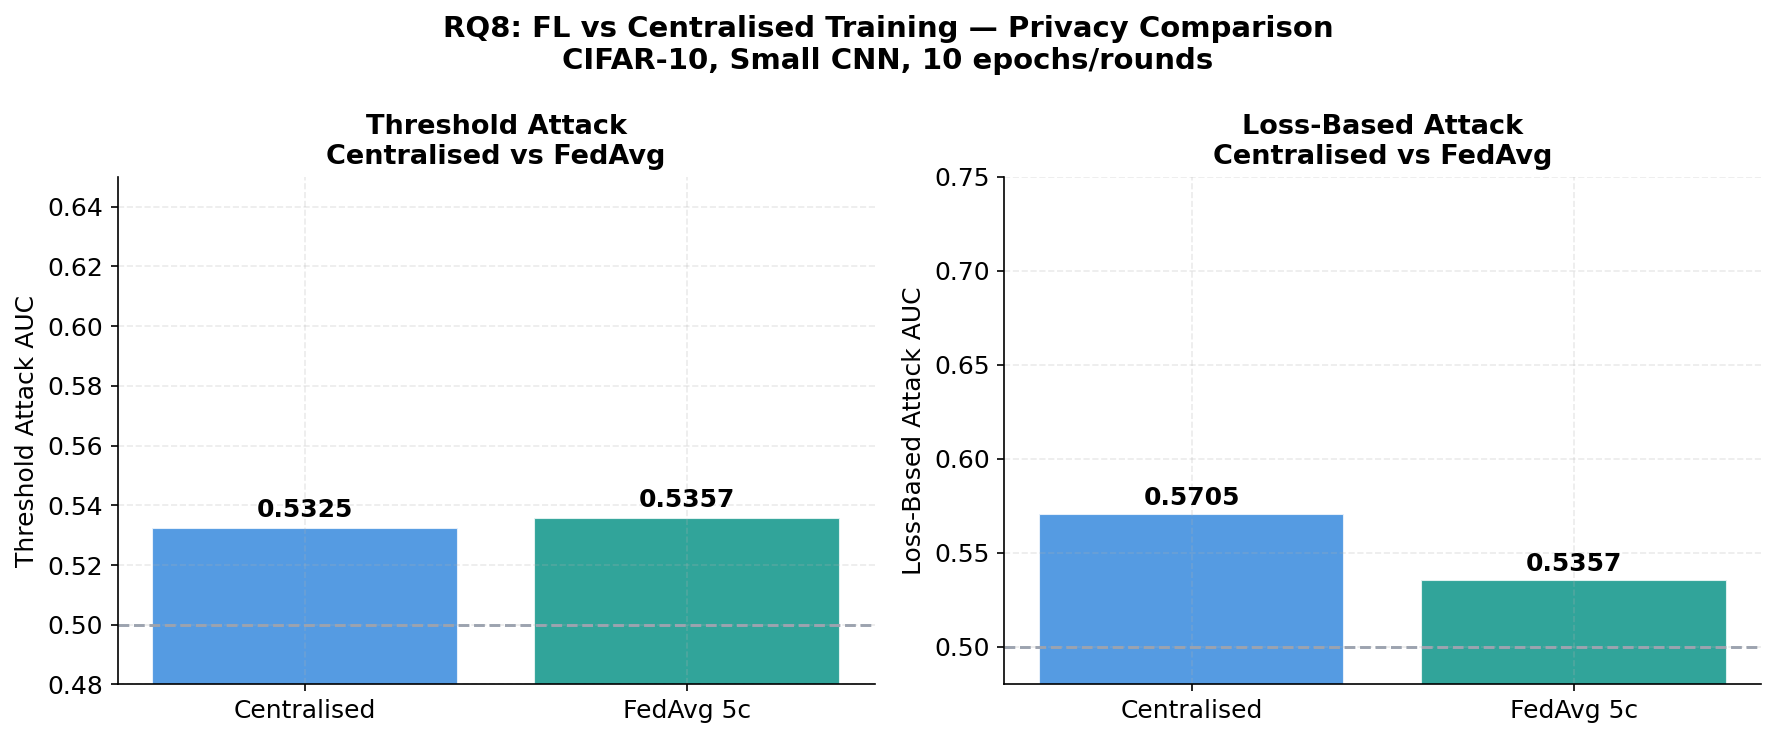

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Done


In [7]:
# ── RQ8: Centralised Training Baseline ───────────────────────────────────────
from sklearn.metrics import roc_auc_score, roc_curve

print('Training centralised model on full CIFAR-10 (no FL)...')

central_model = build_model(NUM_CLASSES, complexity='small')
central_model.compile(
    optimizer=keras.optimizers.Adam(LEARNING_RATE),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
history_central = central_model.fit(
    x_train, y_train,
    epochs=NUM_ROUNDS,
    batch_size=BATCH_SIZE,
    validation_data=(x_test, y_test),
    verbose=1
)
_, central_acc = central_model.evaluate(x_test, y_test, verbose=0)
print(f'Centralised model accuracy: {central_acc:.4f}')

# ── Attack the centralised model ─────────────────────────────────────────────
rng_c      = np.random.default_rng(RANDOM_SEED)
m_idx_c    = rng_c.choice(len(x_train), size=5000, replace=False)
nm_idx_c   = rng_c.choice(len(x_test),  size=5000, replace=False)

m_probs_c  = central_model.predict(x_train[m_idx_c],  batch_size=256, verbose=0)
nm_probs_c = central_model.predict(x_test[nm_idx_c],  batch_size=256, verbose=0)

X_c = np.vstack([m_probs_c, nm_probs_c])
y_c = np.array([1]*5000 + [0]*5000)

# Threshold attack
auc_threshold_c = roc_auc_score(y_c, np.max(X_c, axis=1))

# Loss-based attack
epsilon_c    = 1e-10
m_losses_c   = -np.log(m_probs_c[np.arange(5000), y_train[m_idx_c].astype(int)] + epsilon_c)
nm_losses_c  = -np.log(nm_probs_c[np.arange(5000), y_test[nm_idx_c].astype(int)] + epsilon_c)
all_losses_c = np.concatenate([m_losses_c, nm_losses_c])
auc_loss_c   = roc_auc_score(y_c, -all_losses_c)

# ── Comparison Table ─────────────────────────────────────────────────────────
print('\n' + '═' * 65)
print('RQ8: FL vs Centralised Training — CIFAR-10 Attack Comparison')
print('═' * 65)
print(f'  {"Setting":<35} {"Global Acc":>10} {"Threshold":>10} {"Loss AUC":>10}')
print(f'  {"-"*65}')
print(f'  {"Centralised (single node)":<35} {central_acc:>10.4f} {auc_threshold_c:>10.4f} {auc_loss_c:>10.4f}')
print(f'  {"FedAvg 5 clients (IID)":<35} {global_acc:>10.4f} {auc_threshold:>10.4f} {auc_loss:>10.4f}')
print('═' * 65)
print(f'\n  FL Privacy Gain (Loss AUC reduction): {auc_loss_c - auc_loss:+.4f}')
print(f'  Positive = centralised leaks more, Negative = FL leaks more')

# ── Figure: Comparison Bar Chart ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

settings       = ['Centralised', 'FedAvg 5c']
threshold_aucs = [auc_threshold_c, auc_threshold]
loss_aucs      = [auc_loss_c, auc_loss]
colors         = [BLUE, TEAL]

bars1 = axes[0].bar(settings, threshold_aucs, color=colors, alpha=0.85, edgecolor='white')
for bar, v in zip(bars1, threshold_aucs):
    axes[0].text(bar.get_x() + bar.get_width()/2, v + 0.002,
                 f'{v:.4f}', ha='center', va='bottom', fontsize=12, fontweight='bold')
axes[0].axhline(0.50, **RANDOM_LINE)
axes[0].set_ylabel('Threshold Attack AUC', fontsize=12)
axes[0].set_title('Threshold Attack\nCentralised vs FedAvg', fontsize=13, fontweight='bold')
axes[0].set_ylim(0.48, 0.65)

bars2 = axes[1].bar(settings, loss_aucs, color=colors, alpha=0.85, edgecolor='white')
for bar, v in zip(bars2, loss_aucs):
    axes[1].text(bar.get_x() + bar.get_width()/2, v + 0.002,
                 f'{v:.4f}', ha='center', va='bottom', fontsize=12, fontweight='bold')
axes[1].axhline(0.50, **RANDOM_LINE)
axes[1].set_ylabel('Loss-Based Attack AUC', fontsize=12)
axes[1].set_title('Loss-Based Attack\nCentralised vs FedAvg', fontsize=13, fontweight='bold')
axes[1].set_ylim(0.48, 0.75)

plt.suptitle('RQ8: FL vs Centralised Training — Privacy Comparison\nCIFAR-10, Small CNN, 10 epochs/rounds',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'rq8_fl_vs_centralised.png'), dpi=150, bbox_inches='tight')
plt.show()

from google.colab import files
files.download(os.path.join(OUTPUT_DIR, 'rq8_fl_vs_centralised.png'))
print('Done')


## 7. RQ2 — Effect of Number of Clients on Attack Success

Re-run the full FL training and MIA pipeline with 2, 5, and 10 clients.
Reports Global Accuracy, AUC, and Recall for each configuration.


In [8]:
client_counts = [2, 5, 10]
rq2_results   = {}

for nc in client_counts:
    print(f"\n── {nc} clients ──")
    rq2_results[nc] = run_fl_and_attack(
        num_clients=nc, num_rounds=6, local_epochs=2,
        complexity='small', n_attack_samples=1000
    )
    print(f"  Global acc : {rq2_results[nc]['global_acc']:.4f}")
    print(f"  Attack AUC : {rq2_results[nc]['auc']:.4f}")

print("\nRQ2 complete.")



── 2 clients ──
  Global acc : 0.7225
  Attack AUC : 0.5337

── 5 clients ──
  Global acc : 0.6787
  Attack AUC : 0.5203

── 10 clients ──
  Global acc : 0.6336
  Attack AUC : 0.5008

RQ2 complete.


## 8. RQ3 — Effect of Model Complexity on Privacy Leakage

Re-run with small CNN (~200K params) and large CNN (~1.2M params).
Reports Global Accuracy, AUC, and Recall for each architecture.


In [9]:
complexities = ['small', 'large']
rq3_results  = {}

for c in complexities:
    print(f"\n── '{c}' model ──")
    rq3_results[c] = run_fl_and_attack(
        num_clients=5, num_rounds=6, local_epochs=2,
        complexity=c, n_attack_samples=1000
    )
    print(f"  Global acc : {rq3_results[c]['global_acc']:.4f}")
    print(f"  Attack AUC : {rq3_results[c]['auc']:.4f}")

print("\nRQ3 complete.")



── 'small' model ──
  Global acc : 0.6800
  Attack AUC : 0.5164

── 'large' model ──
  Global acc : 0.7464
  Attack AUC : 0.5356

RQ3 complete.


## 9. RQ2 & RQ3 — Results Plot


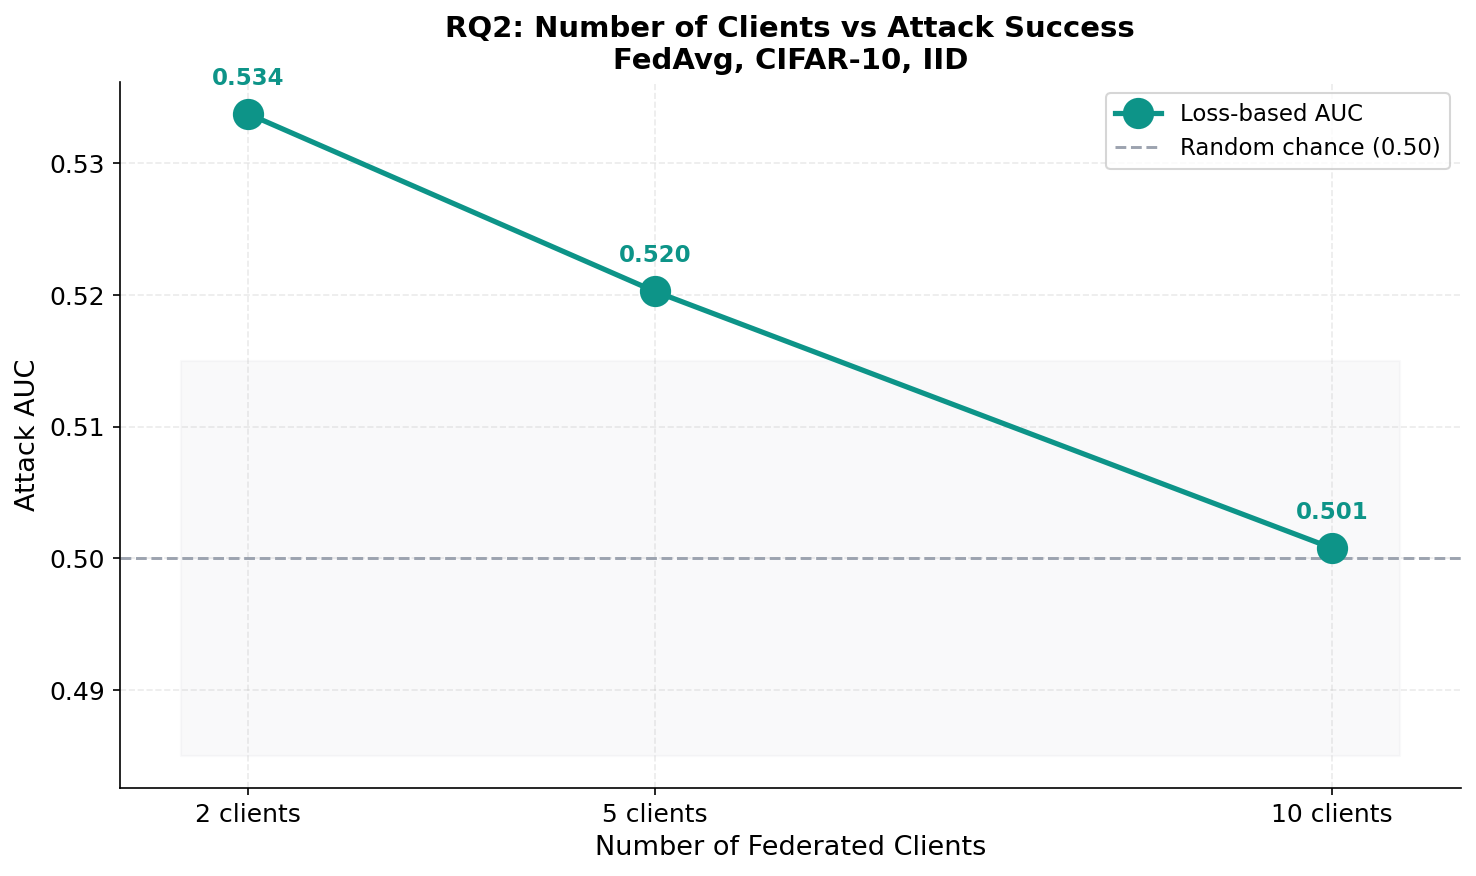

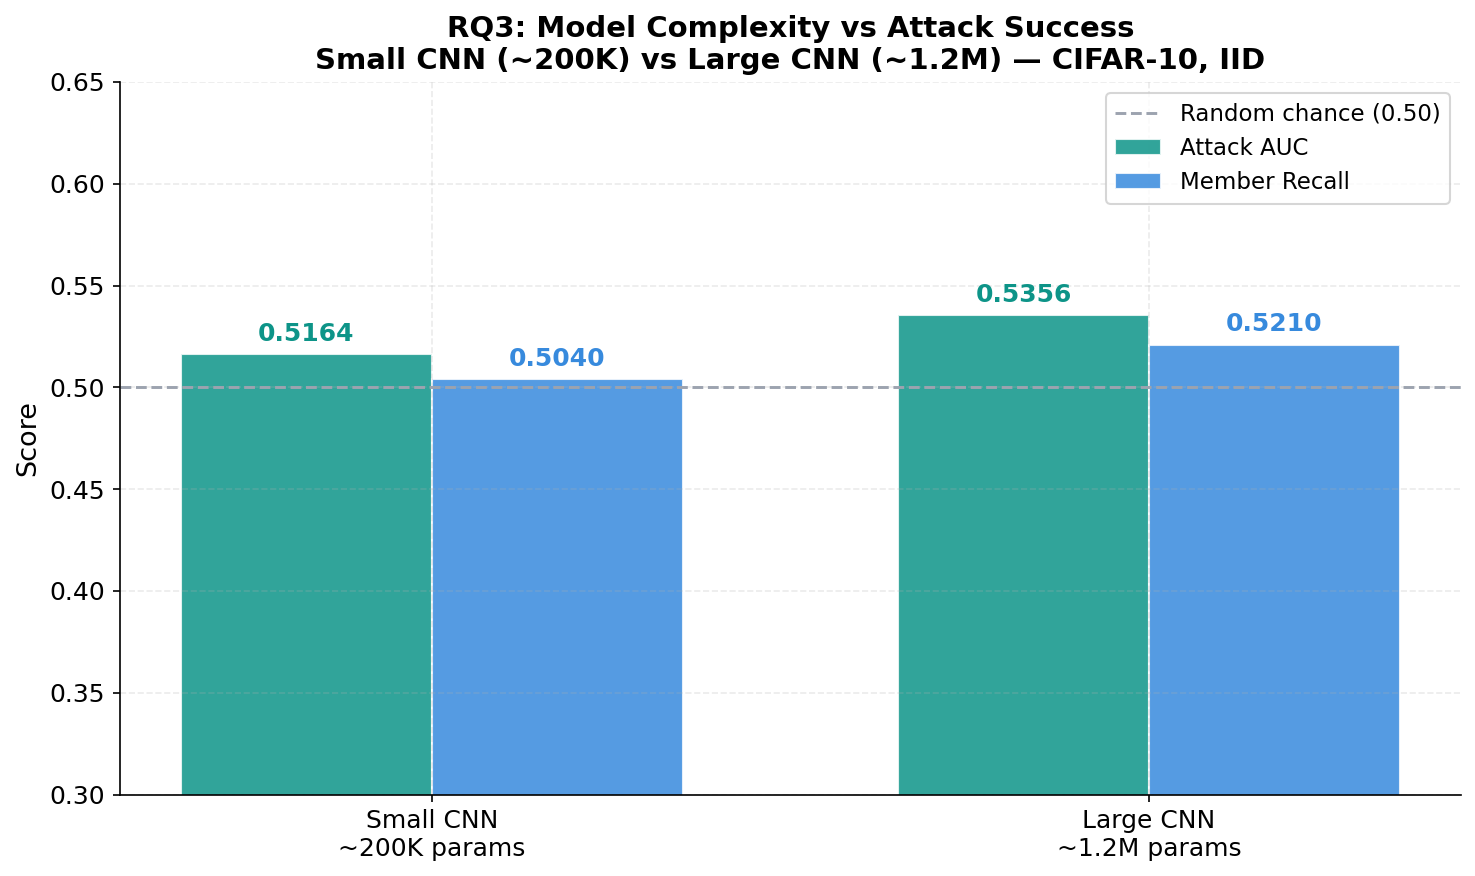

Saved: cifar10_rq2_clients.png and cifar10_rq3_complexity.png


In [10]:
# ── Figure 4: RQ2 Connected dot plot — clients vs AUC ────────────────────────
nc_list  = client_counts
auc_list = [rq2_results[nc]['auc'] for nc in nc_list]

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(nc_list, auc_list, 'o-', color=TEAL, linewidth=2.5,
        markersize=14, label='Loss-based AUC', zorder=3)
for x, y in zip(nc_list, auc_list):
    ax.annotate(f'{y:.3f}', (x, y), textcoords='offset points',
                xytext=(0, 14), ha='center', fontsize=11,
                fontweight='bold', color=TEAL)
ax.axhline(0.50, **RANDOM_LINE)
ax.fill_between([min(nc_list)-0.5, max(nc_list)+0.5],
                0.485, 0.515, alpha=0.06, color='#9CA3AF')
ax.set_xlabel('Number of Federated Clients', fontsize=13)
ax.set_ylabel('Attack AUC', fontsize=13)
ax.set_title('RQ2: Number of Clients vs Attack Success\nFedAvg, CIFAR-10, IID',
             fontsize=14, fontweight='bold')
ax.set_xticks(nc_list)
ax.set_xticklabels([f'{c} clients' for c in nc_list], fontsize=12)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'cifar10_rq2_clients.png'), dpi=150, bbox_inches='tight')
plt.show()

# ── Figure 5: RQ3 Grouped bar chart ──────────────────────────────────────────
model_keys   = list(rq3_results.keys())
auc_vals3    = [rq3_results[c]['auc']    for c in model_keys]
rec_vals3    = [rq3_results[c]['recall'] for c in model_keys]
model_labels = ['Small CNN\n~200K params' if c == 'small' else 'Large CNN\n~1.2M params'
                for c in model_keys]

x3 = np.arange(len(model_keys))
w  = 0.35
fig, ax = plt.subplots(figsize=(10, 6))
b1 = ax.bar(x3 - w/2, auc_vals3, w, color=TEAL, alpha=0.85,
            label='Attack AUC', edgecolor='white')
b2 = ax.bar(x3 + w/2, rec_vals3, w, color=BLUE, alpha=0.85,
            label='Member Recall', edgecolor='white')
for bar, v in zip(b1, auc_vals3):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.004,
            f'{v:.4f}', ha='center', va='bottom', fontsize=12,
            fontweight='bold', color=TEAL)
for bar, v in zip(b2, rec_vals3):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.004,
            f'{v:.4f}', ha='center', va='bottom', fontsize=12,
            fontweight='bold', color=BLUE)
ax.axhline(0.50, **RANDOM_LINE)
ax.set_xticks(x3)
ax.set_xticklabels(model_labels, fontsize=12)
ax.set_ylabel('Score', fontsize=13)
ax.set_title('RQ3: Model Complexity vs Attack Success\nSmall CNN (~200K) vs Large CNN (~1.2M) — CIFAR-10, IID',
             fontsize=14, fontweight='bold')
ax.set_ylim(0.30, 0.65)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'cifar10_rq3_complexity.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: cifar10_rq2_clients.png and cifar10_rq3_complexity.png")

## 10. Summary & Results


In [11]:
print("═" * 60)
print("CIFAR-10 — Results Summary")
print("═" * 60)

print("\nRQ1 — Base attacks (FedAvg, 5 clients, small model)")
print("-" * 60)
print(f"  Global Accuracy   : {global_acc:.4f}")
print(f"  Threshold AUC     : {auc_threshold:.4f}  (random chance = 0.50)")
print(f"  Loss-based AUC    : {auc_loss:.4f}  (random chance = 0.50)")

print("\nRQ2 — Effect of number of clients")
print("-" * 60)
print(f"  {'Clients':<10} {'Global Acc':>12} {'Loss AUC':>10}")
for nc in client_counts:
    r = rq2_results[nc]
    print(f"  {nc:<10} {r['global_acc']:>12.4f} {r['auc']:>10.4f}")

print("\nRQ3 — Effect of model complexity")
print("-" * 60)
print(f"  {'Model':<10} {'Global Acc':>12} {'Loss AUC':>10}")
for c in complexities:
    r = rq3_results[c]
    print(f"  {c:<10} {r['global_acc']:>12.4f} {r['auc']:>10.4f}")

# Save results
all_results = {
    'dataset' : 'CIFAR-10',
    'rq1'     : {'global_acc': float(global_acc),
                 'threshold_auc': float(auc_threshold),
                 'loss_auc': float(auc_loss)},
    'rq2'     : {str(k): {'global_acc': float(d['global_acc']),
                           'auc': float(d['auc'])}
                 for k, d in rq2_results.items()},
    'rq3'     : {k: {'global_acc': float(d['global_acc']),
                     'auc': float(d['auc'])}
                 for k, d in rq3_results.items()}
}
import json as _json
with open(os.path.join(OUTPUT_DIR, 'cifar10_all_results.json'), 'w') as f:
    _json.dump(all_results, f, indent=2)

from google.colab import files
print("\nDownloading result files...")
files.download(os.path.join(OUTPUT_DIR, 'cifar10_all_results.json'))
files.download(os.path.join(OUTPUT_DIR, 'cifar10_convergence.png'))
files.download(os.path.join(OUTPUT_DIR, 'cifar10_rq1_results.png'))
files.download(os.path.join(OUTPUT_DIR, 'cifar10_rq1_roc.png'))
files.download(os.path.join(OUTPUT_DIR, 'cifar10_rq2_clients.png'))
files.download(os.path.join(OUTPUT_DIR, 'cifar10_rq3_complexity.png'))
print("Done.")


════════════════════════════════════════════════════════════
CIFAR-10 — Results Summary
════════════════════════════════════════════════════════════

RQ1 — Base attacks (FedAvg, 5 clients, small model)
------------------------------------------------------------
  Global Accuracy   : 0.7160
  Threshold AUC     : 0.5357  (random chance = 0.50)
  Loss-based AUC    : 0.5357  (random chance = 0.50)

RQ2 — Effect of number of clients
------------------------------------------------------------
  Clients      Global Acc   Loss AUC
  2                0.7225     0.5337
  5                0.6787     0.5203
  10               0.6336     0.5008

RQ3 — Effect of model complexity
------------------------------------------------------------
  Model        Global Acc   Loss AUC
  small            0.6800     0.5164
  large            0.7464     0.5356



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Done.
